<a href="https://colab.research.google.com/github/NethmiAmasha/Deep-Learning-for-Vision/blob/main/EN4554_AS02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#EN4554 Assignment 2 on CNNs
----

Name: Pathirana P.N.A

Index No.: 220449F


### Task 1: Backpropagation

(a) Linear, ReLU, and softmax cross-entropy

In [1]:
import torch

class Linear:
    def __init__(self, in_features, out_features, dtype=torch.float32, generator=None):
        std = (2.0 / in_features) ** 0.5   # Kaiming initialization
        self.W = torch.randn(in_features, out_features, dtype=dtype, generator=generator) * std
        self.b = torch.zeros(out_features, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(dim=0)
        return dout @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values    # numerical stability
        log_probs = shifted - torch.logsumexp(shifted, dim=1, keepdim=True)
        self.probs = log_probs.exp()
        self.y = y
        N = logits.shape[0]
        return -log_probs[torch.arange(N), y].mean()

    def backward(self):
        N = self.probs.shape[0]
        dlogits = self.probs.clone()
        dlogits[torch.arange(N), self.y] -= 1.0
        return dlogits / N

MLP

In [2]:
class MLP:
    def __init__(self, dims, dtype=torch.float32, seed=0):
        g = torch.Generator().manual_seed(seed)
        self.layers = []
        for i in range(len(dims) - 1):
            self.layers.append(Linear(dims[i], dims[i + 1], dtype=dtype, generator=g))
            if i < len(dims) - 2:
                self.layers.append(ReLU())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        grad = self.loss_fn.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def linear_layers(self):
        return [l for l in self.layers if isinstance(l, Linear)]

(b) Verifying the gradients against autograd and against centred finite differences

In [3]:
import torch
import torch.nn.functional as F

def rel_err(a, b, eps=1e-12):
    return ((a - b).norm() / (a.norm() + b.norm() + eps)).item()

def autograd_reference(model, x, y):
    params = []
    for layer in model.linear_layers():
        W = layer.W.clone().requires_grad_(True)
        b = layer.b.clone().requires_grad_(True)
        params.append((W, b))

    h = x
    for i, (W, b) in enumerate(params):
        h = h @ W + b
        if i < len(params) - 1:
            h = torch.relu(h)
    loss = F.cross_entropy(h, y)    # mean softmax cross-entropy
    loss.backward()
    return loss.item(), [(W.grad, b.grad) for W, b in params]

In [4]:
def finite_diff_check(model, x, y, eps=1e-6, n_samples=25, seed=0):
    g = torch.Generator().manual_seed(seed)
    model.loss(x, y)
    model.backward()   # manual gradients
    results = []
    for li, layer in enumerate(model.linear_layers()):
        for name in ("W", "b"):
            param = getattr(layer, name)
            grad = getattr(layer, "d" + name)
            flat = param.view(-1)
            idx = torch.randperm(flat.numel(), generator=g)[:n_samples]
            ana = grad.reshape(-1)[idx]  # analytic gradient at the sampled entries
            num = torch.empty_like(ana)
            for k, i in enumerate(idx.tolist()):
                orig = flat[i].item()
                flat[i] = orig + eps
                loss_plus = model.loss(x, y).item()
                flat[i] = orig - eps
                loss_minus = model.loss(x, y).item()
                flat[i] = orig
                num[k] = (loss_plus - loss_minus) / (2 * eps)
            results.append((f"layer{li}.{name}",
                            rel_err(ana, num),
                            torch.allclose(ana, num, rtol=1e-5, atol=1e-7)))
    return results

In [5]:
torch.manual_seed(0)
model = MLP([3072, 64, 32, 10], dtype=torch.float64, seed=0)
x = torch.randn(16, 3072, dtype=torch.float64)
y = torch.randint(0, 10, (16,))

# manual vs autograd
loss = model.loss(x, y).item()
model.backward()
ag_loss, ag_grads = autograd_reference(model, x, y)
print(f"loss  manual={loss:.12f}  autograd={ag_loss:.12f}\n")

print("=== Manual vs autograd ===")
for li, (layer, (gW, gb)) in enumerate(zip(model.linear_layers(), ag_grads)):
    for name, mine, ref in (("W", layer.dW, gW), ("b", layer.db, gb)):
        print(f"layer{li}.{name}: rel err = {rel_err(mine, ref):.2e}   "
              f"allclose = {torch.allclose(mine, ref, rtol=1e-7, atol=1e-10)}")

# manual vs finite differences
print("\n=== Manual vs centred finite differences ===")
for name, err, ok in finite_diff_check(model, x, y):
    print(f"{name}: rel err = {err:.2e}   allclose = {ok}")

loss  manual=3.217372143849  autograd=3.217372143849

=== Manual vs autograd ===
layer0.W: rel err = 8.57e-17   allclose = True
layer0.b: rel err = 7.63e-17   allclose = True
layer1.W: rel err = 5.33e-17   allclose = True
layer1.b: rel err = 5.53e-17   allclose = True
layer2.W: rel err = 4.61e-17   allclose = True
layer2.b: rel err = 2.30e-17   allclose = True

=== Manual vs centred finite differences ===
layer0.W: rel err = 2.09e-09   allclose = True
layer0.b: rel err = 1.54e-09   allclose = True
layer1.W: rel err = 1.46e-09   allclose = True
layer1.b: rel err = 1.40e-09   allclose = True
layer2.W: rel err = 8.26e-10   allclose = True
layer2.b: rel err = 6.59e-10   allclose = True


The manual gradients match autograd to ~1e-17 relative error and centred finite differences to ~1e-9, with torch.allclose passing for every parameter. So, the backward pass is correct. The check ran in float64 on a smaller MLP (3072-64-32-10, 16 random inputs), and the finite-difference check tested 25 randomly sampled entries per tensor with ε = 1e-6.

 (c) Training with SGD on flattened CIFAR-10 images

Images are flattened to 3072-d vectors. The manual MLP is trained with plain minibatch SGD.

Hyperparameters: learning rate = 0.05, batch size = 128, 20 epochs, data reshuffled each epoch, seed 0.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
!mkdir -p ./data
!cp -r /content/drive/MyDrive/cifar_data/* ./data/

In [8]:
import random
import numpy as np
import torch
import torchvision

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Load the raw training set (uint8 images, shape (50000, 32, 32, 3))
full_train = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
X_all = torch.from_numpy(full_train.data).permute(0, 3, 1, 2).float() / 255.0
y_all = torch.tensor(full_train.targets, dtype=torch.long)

# 45k / 5k split with a fixed permutation
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
train_x, train_y = X_all[tr_idx], y_all[tr_idx]
val_x, val_y = X_all[va_idx], y_all[va_idx]

# Per-channel normalization using training set only
mean = train_x.mean(dim=(0, 2, 3), keepdim=True)
std = train_x.std(dim=(0, 2, 3), keepdim=True)
train_x = (train_x - mean) / std
val_x = (val_x - mean) / std

print(train_x.shape, val_x.shape, train_y.shape, val_y.shape)
print("train mean per channel:", train_x.mean(dim=(0, 2, 3)))
print("train std per channel: ", train_x.std(dim=(0, 2, 3)))

torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([45000]) torch.Size([5000])
train mean per channel: tensor([1.8961e-07, 5.6320e-06, 2.1302e-06])
train std per channel:  tensor([1., 1., 1.])


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten images
Xtr, ytr = train_x.reshape(len(train_x), -1), train_y
Xva, yva = val_x.reshape(len(val_x), -1), val_y
print(Xtr.shape, Xva.shape)

def accuracy(model, X, y, bs=1000):
    correct = 0
    for i in range(0, len(X), bs):
        correct += (model.forward(X[i:i+bs]).argmax(dim=1) == y[i:i+bs]).sum().item()
    return correct / len(X)

def eval_loss(model, X, y, bs=1000):
    total = 0.0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i+bs], y[i:i+bs]
        total += model.loss(xb, yb).item() * len(xb)
    return total / len(X)

def sgd_step(model, lr):
    for layer in model.linear_layers():
        layer.W -= lr * layer.dW
        layer.b -= lr * layer.db

torch.Size([45000, 3072]) torch.Size([5000, 3072])


In [10]:
def train_mlp(dims, lr, epochs, batch_size, seed=0):
    model = MLP(dims, seed=seed)
    g = torch.Generator().manual_seed(seed)
    hist = {"iter_loss": [], "train_loss": [], "val_loss": [], "val_acc": []}
    N = len(Xtr)

    for ep in range(epochs):
        perm = torch.randperm(N, generator=g)
        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            loss = model.loss(Xtr[idx], ytr[idx])  # forward
            model.backward()  # manual backward
            sgd_step(model, lr)  # parameter update
            hist["iter_loss"].append(loss.item())

        hist["train_loss"].append(eval_loss(model, Xtr, ytr))
        hist["val_loss"].append(eval_loss(model, Xva, yva))
        hist["val_acc"].append(accuracy(model, Xva, yva))
        print(f"epoch {ep+1:2d} | train loss {hist['train_loss'][-1]:.4f} | "
              f"val loss {hist['val_loss'][-1]:.4f} | val acc {hist['val_acc'][-1]:.4f}")
    return model, hist

mlp, hist = train_mlp([3072, 512, 256, 10], lr=0.05, epochs=20, batch_size=128)

epoch  1 | train loss 1.4337 | val loss 1.5851 | val acc 0.4410
epoch  2 | train loss 1.2957 | val loss 1.5312 | val acc 0.4706
epoch  3 | train loss 1.2256 | val loss 1.5402 | val acc 0.4698
epoch  4 | train loss 1.0560 | val loss 1.4680 | val acc 0.5002
epoch  5 | train loss 0.9900 | val loss 1.4727 | val acc 0.4978
epoch  6 | train loss 0.9105 | val loss 1.4869 | val acc 0.5090
epoch  7 | train loss 0.8201 | val loss 1.4991 | val acc 0.5064
epoch  8 | train loss 0.8055 | val loss 1.5666 | val acc 0.4970
epoch  9 | train loss 0.6829 | val loss 1.5518 | val acc 0.5026
epoch 10 | train loss 0.7120 | val loss 1.6819 | val acc 0.4866
epoch 11 | train loss 0.6372 | val loss 1.6961 | val acc 0.4878
epoch 12 | train loss 0.6477 | val loss 1.8777 | val acc 0.4892
epoch 13 | train loss 0.5057 | val loss 1.8010 | val acc 0.4970
epoch 14 | train loss 0.5514 | val loss 1.9347 | val acc 0.4716
epoch 15 | train loss 0.4172 | val loss 1.8856 | val acc 0.4892
epoch 16 | train loss 0.3675 | val loss 

Plotting the loss and report validation accuracy.

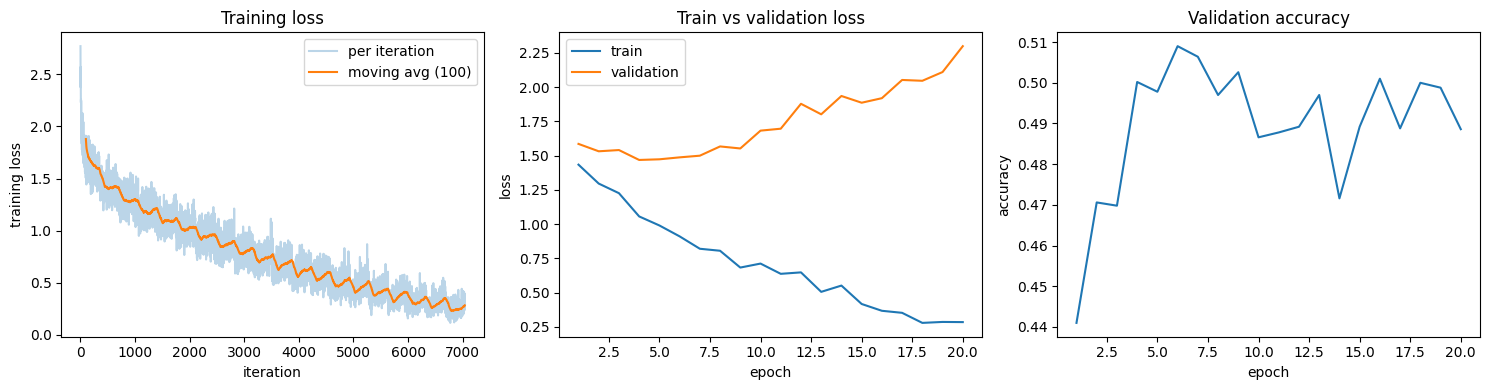

Final validation accuracy: 0.4886
Best validation accuracy:  0.5090 (epoch 6)


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Training loss per iteration
it = np.array(hist["iter_loss"])
k = 100
ax[0].plot(it, alpha=0.3, label="per iteration")
ax[0].plot(np.arange(k - 1, len(it)), np.convolve(it, np.ones(k) / k, mode="valid"),
           label=f"moving avg ({k})")
ax[0].set(xlabel="iteration", ylabel="training loss", title="Training loss")
ax[0].legend()

# Epoch-level train vs validation loss
ep = np.arange(1, len(hist["train_loss"]) + 1)
ax[1].plot(ep, hist["train_loss"], label="train")
ax[1].plot(ep, hist["val_loss"], label="validation")
ax[1].set(xlabel="epoch", ylabel="loss", title="Train vs validation loss")
ax[1].legend()

# Validation accuracy
ax[2].plot(ep, hist["val_acc"])
ax[2].set(xlabel="epoch", ylabel="accuracy", title="Validation accuracy")

plt.tight_layout()
plt.show()

print(f"Final validation accuracy: {hist['val_acc'][-1]:.4f}")
print(f"Best validation accuracy:  {max(hist['val_acc']):.4f} (epoch {int(np.argmax(hist['val_acc'])) + 1})")

The MLP reaches a final validation accuracy of 48.86% (best 50.9% at epoch 6). Training loss falls from 1.43 after epoch 1 to 0.28 after epoch 20.

The per-iteration loss is noisy because each step uses a 128-image minibatch, while the moving average shows a steady decline. Validation loss is lowest at epoch 4 (1.46) and then rises to 2.3 while training loss keeps decreasing. This shows that the network overfits from about epoch 4 onward. An MLP on flattened pixels ignores spatial structure and has no translation invariance. This limits its accuracy.

(d) Plotting the per-layer gradient norm at initialization with sigmoid and with ReLU for a 10-layer MLP

A 10-layer MLP is built with sigmoid and with ReLU activations. Both use the same seed. Therefore they have identical Kaiming-initialized weights and only the activation differs. At initialization, one forward/backward pass is run on 256 training images and the Frobenius norm of `dW` for each linear layer is recorded. The results are averaged over 5 seeds.

In [12]:
class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)

def make_mlp(dims, act, seed=0):
    model = MLP(dims, seed=seed)
    if act == "sigmoid":
        model.layers = [Sigmoid() if isinstance(l, ReLU) else l for l in model.layers]
    return model

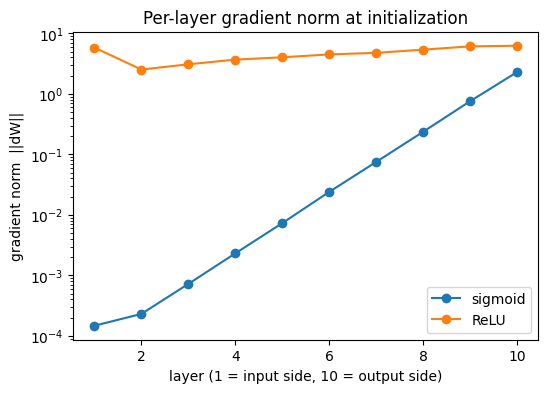

sigmoid  layer1 = 1.47e-04, layer10 = 2.30e+00, ratio layer10/layer1 = 1.6e+04
relu     layer1 = 5.82e+00, layer10 = 6.25e+00, ratio layer10/layer1 = 1.1e+00


In [13]:
dims = [3072] + [256] * 9 + [10]
xb, yb = Xtr[:256], ytr[:256]

def layer_grad_norms(model, x, y):
    model.loss(x, y)
    model.backward()
    return [l.dW.norm().item() for l in model.linear_layers()]

seeds = range(5)
norms = {act: np.array([layer_grad_norms(make_mlp(dims, act, seed=s), xb, yb) for s in seeds])
         for act in ("sigmoid", "relu")}

layers = np.arange(1, 11)
plt.figure(figsize=(6, 4))
for act, label in (("sigmoid", "sigmoid"), ("relu", "ReLU")):
    plt.plot(layers, norms[act].mean(axis=0), marker="o", label=label)
plt.yscale("log")
plt.xlabel("layer (1 = input side, 10 = output side)")
plt.ylabel("gradient norm  ||dW||")
plt.title("Per-layer gradient norm at initialization")
plt.legend()
plt.show()

for act in norms:
    m = norms[act].mean(axis=0)
    print(f"{act:8s} layer1 = {m[0]:.2e}, layer10 = {m[-1]:.2e}, ratio layer10/layer1 = {m[-1]/m[0]:.1e}")

When using sigmoid, the gradient norm drops steadily towards the input. Layer 1 has norm 1.47e-4 and 2.3 at layer 10 which gives a ratio of about 1.6e4. When using ReLU, the norm for layer 1 is 5.82 and norm for layer 10 is 6.25 which gives a ratio of only 1.1.

Backpropagation multiplies the gradient by the activation derivative at every layer. The sigmoid derivative is at most 0.25, and smaller when units saturate, so the gradient shrinks by a roughly constant factor per layer and decays exponentially with depth. The early layers get almost no learning signal, and with the same learning rate they learn far more slowly than the layers near the output. The ReLU derivative is exactly 1 for active units, so the gradient passes through without shrinkage, and Kaiming initialization keeps the signal variance stable from layer to layer. Both networks use the same Kaiming-initialized weights, so the difference comes from the activation function. This is why ReLU networks can be trained at depths where sigmoid networks cannot.

### Task 2: Optimizers

(a) SGD with momentum and Adam

- SGD with momentum: `buf ← μ·buf + g`, `p ← p − lr·buf`. With `μ = 0` it reduces to plain SGD.
- Adam: `m ← β₁m + (1−β₁)g`, `v ← β₂v + (1−β₂)g²`, `m̂ = m/(1−β₁ᵗ)`, `v̂ = v/(1−β₂ᵗ)`, `p ← p − lr·m̂/(√v̂ + ε)`.

In [14]:
import torch
import torch.nn.functional as F
from torch.optim import Optimizer

class SGDMomentum(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if "buf" not in state:
                    state["buf"] = p.grad.clone() # first step: buf = g
                else:
                    state["buf"].mul_(group["momentum"]).add_(p.grad)
                p.add_(state["buf"], alpha=-group["lr"])
        return loss


class Adam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g, state = p.grad, self.state[p]
                if not state:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]
                m.mul_(b1).add_(g, alpha=1 - b1)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = m / (1 - b1 ** t)  # bias correction
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group["eps"]), value=-group["lr"])
        return loss

Comparison with `torch.optim`

In [15]:
def run(opt_cls, steps=100, **kw):
    torch.manual_seed(0)
    net = torch.nn.Sequential(torch.nn.Linear(20, 16), torch.nn.ReLU(),
                              torch.nn.Linear(16, 5)).double()
    opt = opt_cls(net.parameters(), **kw)
    g = torch.Generator().manual_seed(1)
    X = torch.randn(64, 20, generator=g, dtype=torch.float64)
    y = torch.randint(0, 5, (64,), generator=g)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(net(X), y).backward()
        opt.step()
    return torch.cat([p.detach().flatten() for p in net.parameters()])

checks = [("SGD (momentum=0)", SGDMomentum, torch.optim.SGD, dict(lr=0.05, momentum=0.0)),
          ("SGD + momentum",   SGDMomentum, torch.optim.SGD, dict(lr=0.05, momentum=0.9)),
          ("Adam",             Adam,        torch.optim.Adam, dict(lr=1e-2))]

for name, mine, ref, kw in checks:
    a, b = run(mine, **kw), run(ref, **kw)
    print(f"{name:17s} max |diff| = {(a - b).abs().max().item():.2e}   "
          f"allclose = {torch.allclose(a, b, rtol=1e-9, atol=1e-12)}")

SGD (momentum=0)  max |diff| = 0.00e+00   allclose = True
SGD + momentum    max |diff| = 0.00e+00   allclose = True
Adam              max |diff| = 5.55e-16   allclose = True


Both custom optimizers match their `torch.optim` counterparts. After 100 steps the maximum parameter difference is 0 for SGD, with and without momentum and 5.55e-16 for Adam, and `torch.allclose` passes in all three cases. The SGD results are bit-identical because the update uses the same operations in the same order as PyTorch's. The tiny Adam difference is floating-point rounding only.

(b) Plotting the trajectories of SGD, SGD with momentum, and Adam

`f(x, y) = ½(x² + 50y²)` has gradient `(x, 50y)`. So, it is 50 times steeper in `y` than in `x`. I take starting point as (10, 1), and run 150 steps of:
- SGD with a learning rate 0.03
- SGD with momentum with a learning rate of 0.03 and momentum of 0.9
- Adam with a learning rate of 0.3

In [16]:
import numpy as np
import matplotlib.pyplot as plt

def f(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(opt_cls, steps=150, **kw):
    p = torch.tensor([10.0, 1.0], requires_grad=True)
    opt = opt_cls([p], **kw)
    path = [p.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad()
        f(p).backward()
        opt.step()
        path.append(p.detach().numpy().copy())
    return np.array(path)

paths = {
    "SGD (lr 0.03)": trajectory(SGDMomentum, lr=0.03, momentum=0.0),
    "SGD + momentum (lr 0.03, μ 0.9)": trajectory(SGDMomentum, lr=0.03, momentum=0.9),
    "Adam (lr 0.3)": trajectory(Adam, lr=0.3),
}

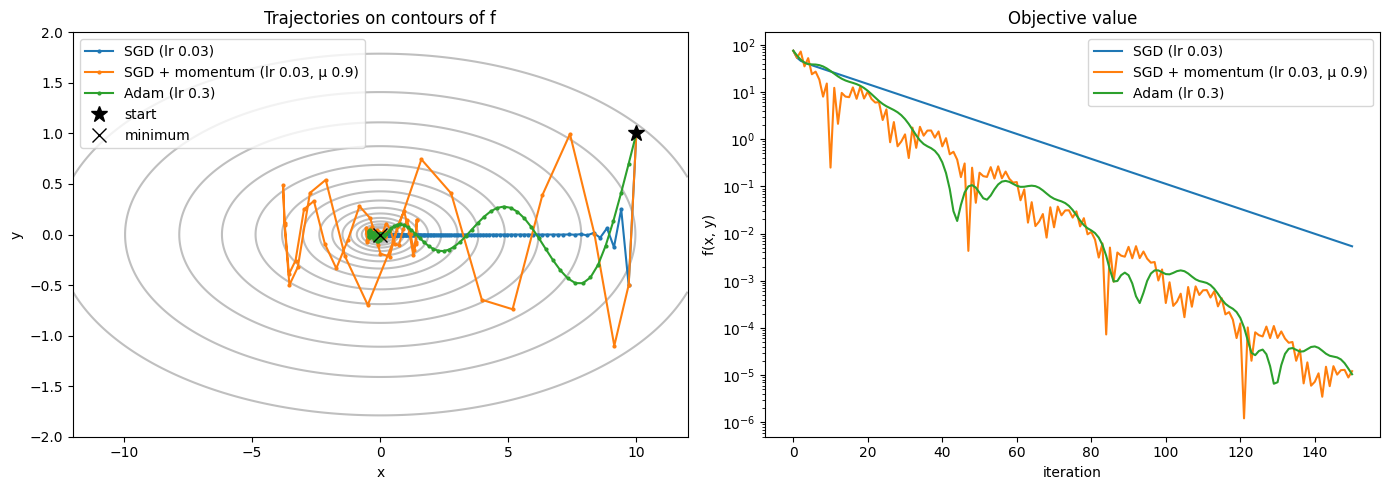

SGD (lr 0.03)                      final (x, y) = (+1.04e-01, +0.00e+00),  f = 5.38e-03
SGD + momentum (lr 0.03, μ 0.9)    final (x, y) = (+3.74e-03, -4.54e-04),  f = 1.21e-05
Adam (lr 0.3)                      final (x, y) = (-4.55e-03, +6.23e-05),  f = 1.04e-05


In [17]:
# plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# contours and trajectories
xs, ys = np.linspace(-12, 12, 400), np.linspace(-2, 2, 400)
X, Y = np.meshgrid(xs, ys)
Z = 0.5 * (X ** 2 + 50 * Y ** 2)
ax[0].contour(X, Y, Z, levels=np.geomspace(0.1, 80, 15), colors="gray", alpha=0.5)
for name, path in paths.items():
    ax[0].plot(path[:, 0], path[:, 1], marker=".", markersize=4, label=name)
ax[0].plot(*paths["Adam (lr 0.3)"][0], "k*", markersize=12, label="start")
ax[0].plot(0, 0, "kx", markersize=10, label="minimum")
ax[0].set(xlabel="x", ylabel="y", title="Trajectories on contours of f")
ax[0].legend()

# f vs iteration
for name, path in paths.items():
    ax[1].plot(0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2), label=name)
ax[1].set(yscale="log", xlabel="iteration", ylabel="f(x, y)", title="Objective value")
ax[1].legend()

plt.tight_layout()
plt.show()

for name, path in paths.items():
    print(f"{name:34s} final (x, y) = ({path[-1,0]:+.2e}, {path[-1,1]:+.2e}),  f = {0.5*(path[-1,0]**2 + 50*path[-1,1]**2):.2e}")

The left plot shows the trajectories of the three optimizers over the contours of `f`. Plain SGD drops to `y ≈ 0` within a few steps and then goes along the flat `x` axis. SGD with momentum takes a zigzag like path with large swings in `y` and `x`, but it gets close to the minimum. Adam takes a smooth, curved path.

The right plot shows `f` against iteration on a log scale. Here, SGD decreases as a straight line, and with momentum it decreases fastest but very noisily, and Adam decreases almost as fast with oscillations of much smaller amplitude.

According to the plots, the step size of plain SGD is limited by the steep direction and the `y` coordinate converges faster than `x`. After 150 steps `x` is still 0.104 eventhough `y` became 0 and `f = 5.38e-03`. SGD with momentum accumulates gradient along the `x` direction, which speeds up progress in that direction with an effective step size. But, it has a zig-zag path. Its final `f = 1.21e-05` is much lower than SGD's. In Adam both directions move at a similar speed, and its path shows a less zigzag behaviour than that of SGD with momentum. Its final `f = 1.04e-05` is much lower than SGD's.

This shows that for an ill-conditioned problem plain SGD is slow because one learning rate is not suitable, whereas momentum and Adam both fix this issue.

(c) Training a small CNN with three optimizers at three learning rates

- A small CNN with 3 convolution blocks (with conv3×3, ReLU, maxpool each) with 32/64/128 channels, then a linear classifier
- ~290k parameters, no batch norm
- Trained for 10 epochs with batch size 128 and seed 0
- Trained using plain SGD, SGD with momentum (μ = 0.9) and Adam, each at three learning rates. Their learning rates differ as their useful ranges differ.
- SGD is trained for the learning rates 0.003, 0.01 and 0.03.
- SGD with momentum is trained for the learning rates 0.001, 0.003 and 0.01.
- Adam is trained for the learning rates 1e-4, 1e-3 and 1e-2

In [18]:
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

Xtr_g, ytr_g = train_x.to(device), train_y.to(device)
Xva_g, yva_g = val_x.to(device), val_y.to(device)

def make_cnn():
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                         nn.Flatten(), nn.Linear(128 * 4 * 4, 10))

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X)

def train_cnn(opt_cls, lr, epochs=10, batch_size=128, seed=0, **kw):
    torch.manual_seed(seed)
    model = make_cnn().to(device)
    opt = opt_cls(model.parameters(), lr=lr, **kw)
    g = torch.Generator(device=device).manual_seed(seed)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_g), device=device, generator=g)
        running = 0.0
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = F.cross_entropy(model(Xtr_g[idx]), ytr_g[idx])
            loss.backward()
            opt.step()
            running += loss.item() * len(idx)
        vl, va = evaluate(model, Xva_g, yva_g)
        hist["train_loss"].append(running / len(perm))
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)
    return hist

print("parameters:", sum(p.numel() for p in make_cnn().parameters()))

device: cuda
parameters: 113738


In [19]:
grid = {
    "SGD": (SGDMomentum, dict(momentum=0.0), [0.003, 0.01, 0.03]),
    "SGD+momentum": (SGDMomentum, dict(momentum=0.9), [0.001, 0.003, 0.01]),
    "Adam": (Adam,        dict(),             [1e-4, 1e-3, 1e-2]),
}

results = {}
for name, (cls, kw, lrs) in grid.items():
    for lr in lrs:
        h = train_cnn(cls, lr, **kw)
        results[(name, lr)] = h
        print(f"{name:13s} lr={lr:<7g} final val acc = {h['val_acc'][-1]:.4f}   "
              f"final train loss = {h['train_loss'][-1]:.4f}")

SGD           lr=0.003   final val acc = 0.4560   final train loss = 1.4840
SGD           lr=0.01    final val acc = 0.5720   final train loss = 1.1220
SGD           lr=0.03    final val acc = 0.6964   final train loss = 0.7934
SGD+momentum  lr=0.001   final val acc = 0.6036   final train loss = 1.0958
SGD+momentum  lr=0.003   final val acc = 0.6962   final train loss = 0.7559
SGD+momentum  lr=0.01    final val acc = 0.7308   final train loss = 0.4499
Adam          lr=0.0001  final val acc = 0.6262   final train loss = 1.0321
Adam          lr=0.001   final val acc = 0.7354   final train loss = 0.3924
Adam          lr=0.01    final val acc = 0.5462   final train loss = 1.2057


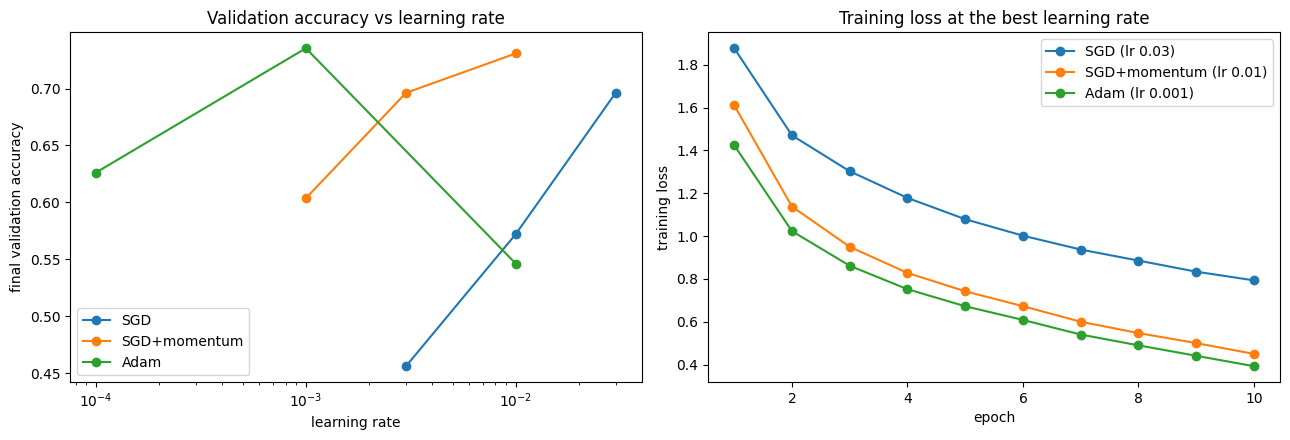

Best learning rates: {'SGD': 0.03, 'SGD+momentum': 0.01, 'Adam': 0.001}
Best validation accuracy: {'SGD': 0.6964, 'SGD+momentum': 0.7308, 'Adam': 0.7354}


In [20]:
# Plotting
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# validation accuracy vs learning rate
for name, (_, _, lrs) in grid.items():
    ax[0].plot(lrs, [results[(name, lr)]["val_acc"][-1] for lr in lrs], marker="o", label=name)
ax[0].set(xscale="log", xlabel="learning rate", ylabel="final validation accuracy",
          title="Validation accuracy vs learning rate")
ax[0].legend()

# training loss at best rate
best = {}
for name, (_, _, lrs) in grid.items():
    best[name] = max(lrs, key=lambda lr: results[(name, lr)]["val_acc"][-1])
    h = results[(name, best[name])]
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], marker="o",
               label=f"{name} (lr {best[name]:g})")
ax[1].set(xlabel="epoch", ylabel="training loss", title="Training loss at the best learning rate")
ax[1].legend()

plt.tight_layout()
plt.show()

print("Best learning rates:", best)
print("Best validation accuracy:",
      {n: round(results[(n, best[n])]["val_acc"][-1], 4) for n in best})

Best final validation accuracy per optimizer is, SGD 69.6% (lr 0.03), SGD with momentum 73% (lr 0.01), Adam 73.5% (lr 0.001). The left plot shows validation accuracy against learning rate on a log axis, and the right plot shows the training loss at each optimizer's best rate. SGD with momentum and Adam give almost same accuracy and both are relatively better than plain SGD.

**Sensitivity**
- **SGD** is very sensitive and, within the tested learning rates, it is still improving at the largest rate. Its accuracy rises from 45.6% (lr 0.003) to 57.2% (0.01) to 69.6% (0.03). The best rate is given at the highest learning rate.
- **SGD with momentum** shows the same pattern: 60.3%, 69.6%, 73.1% for lr 0.001, 0.003, 0.01. Its best rate is also at the highest learning rate.
- **Adam** behaves differently giving 62.6% at 1e-4, 73.5% at 1e-3, and 54.6% at 1e-2. A too small rate undertrains it and a too large rate makes it unstable.

At the best rates, Adam's loss falls fastest, then momentum, then SGD. The ordering of training loss matches the ordering of validation accuracy, so the faster optimizers are also generalizing better rather than overfitting within 10 epochs.


### Task 3: Regularization and residual connections

(a) Training a small CNN with batch norm on 5k training images

A batch-norm CNN with 3 convolution blocks and 32/64/128 channels, then dropout and a linear layer is trained on the first 5,000 training images and validated on the 5,000-image validation split. SGD with momentum is used with momentum 0.9, learning rate 0.03, batch size 128, 50 epochs, cosine learning-rate decay and seed 0. Compared with baseline, weight decay (5e-4), dropout (p = 0.3), flip+crop, cutout (8×8), mixup (α = 0.4) and all combined. Cutout, mixup and flip+crop are implemented by hand. Train accuracy is measured on the clean training subset in eval mode.

In [21]:
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

device = "cuda" if torch.cuda.is_available() else "cpu"
X5, y5 = train_x[:5000].to(device), train_y[:5000].to(device)
Xv, yv = val_x.to(device), val_y.to(device)

# augmentations
def flip_crop(x, pad=4):
    N = x.shape[0]
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad,) * 4)  # zero padding
    dy = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    dx = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    ar = torch.arange(32, device=x.device)
    iy = (dy[:, None] + ar)[:, None, :, None]
    ix = (dx[:, None] + ar)[:, None, None, :]
    n = torch.arange(N, device=x.device)[:, None, None, None]
    c = torch.arange(3, device=x.device)[None, :, None, None]
    return xp[n, c, iy, ix]

def cutout(x, size=8):
    N = x.shape[0]
    cy = torch.randint(0, 32, (N,), device=x.device)
    cx = torch.randint(0, 32, (N,), device=x.device)
    ar = torch.arange(32, device=x.device)
    my = ((ar[None, :] >= (cy[:, None] - size // 2)) & (ar[None, :] < (cy[:, None] + size // 2)))
    mx = ((ar[None, :] >= (cx[:, None] - size // 2)) & (ar[None, :] < (cx[:, None] + size // 2)))
    mask = (my[:, :, None] & mx[:, None, :])[:, None]
    return x.masked_fill(mask, 0.0)

def mixup(x, y, alpha=0.4):
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(x.shape[0], device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

def make_bn_cnn(p_drop=0.0):
    def block(i, o):
        return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o),
                             nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.Flatten(),
                         nn.Dropout(p_drop), nn.Linear(128 * 4 * 4, 10))

@torch.no_grad()
def acc(model, X, y, bs=1000):
    model.eval()
    return sum((model(X[i:i+bs]).argmax(1) == y[i:i+bs]).sum().item() for i in range(0, len(X), bs)) / len(X)

In [22]:
# training
def train_reg(wd=0.0, p_drop=0.0, fc=False, co=False, mix=False, epochs=50, bs=128, lr=0.03, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_bn_cnn(p_drop).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {"train_acc": [], "val_acc": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X5), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = X5[idx], y5[idx]
            if fc:  xb = flip_crop(xb)
            if co:  xb = cutout(xb)
            opt.zero_grad()
            if mix:
                xb, ya, yb2, lam = mixup(xb, yb)
                out = model(xb)
                loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb2)
            else:
                loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
        sched.step()
        hist["train_acc"].append(acc(model, X5, y5))
        hist["val_acc"].append(acc(model, Xv, yv))
    return hist

configs = {
    "Baseline":     dict(),
    "Weight decay": dict(wd=5e-4),
    "Dropout":      dict(p_drop=0.3),
    "Flip+crop":    dict(fc=True),
    "Cutout":       dict(co=True),
    "Mixup":        dict(mix=True),
    "All combined": dict(wd=5e-4, p_drop=0.3, fc=True, co=True, mix=True),
}

hists = {}
for name, kw in configs.items():
    hists[name] = train_reg(**kw)
    print(f"{name:13s} train {hists[name]['train_acc'][-1]:.4f}  val {hists[name]['val_acc'][-1]:.4f}")

Baseline      train 0.9936  val 0.6100
Weight decay  train 0.9960  val 0.6108
Dropout       train 0.9910  val 0.6572
Flip+crop     train 0.7882  val 0.6874
Cutout        train 0.9530  val 0.6218
Mixup         train 0.9022  val 0.6176
All combined  train 0.6500  val 0.6024


,Train acc,Val acc,Gap
Setting,,,
Baseline,0.9936,0.6100,0.3836
Weight decay,0.9960,0.6108,0.3852
Dropout,0.9910,0.6572,0.3338
Flip+crop,0.7882,0.6874,0.1008
Cutout,0.9530,0.6218,0.3312
Mixup,0.9022,0.6176,0.2846
All combined,0.6500,0.6024,0.0476


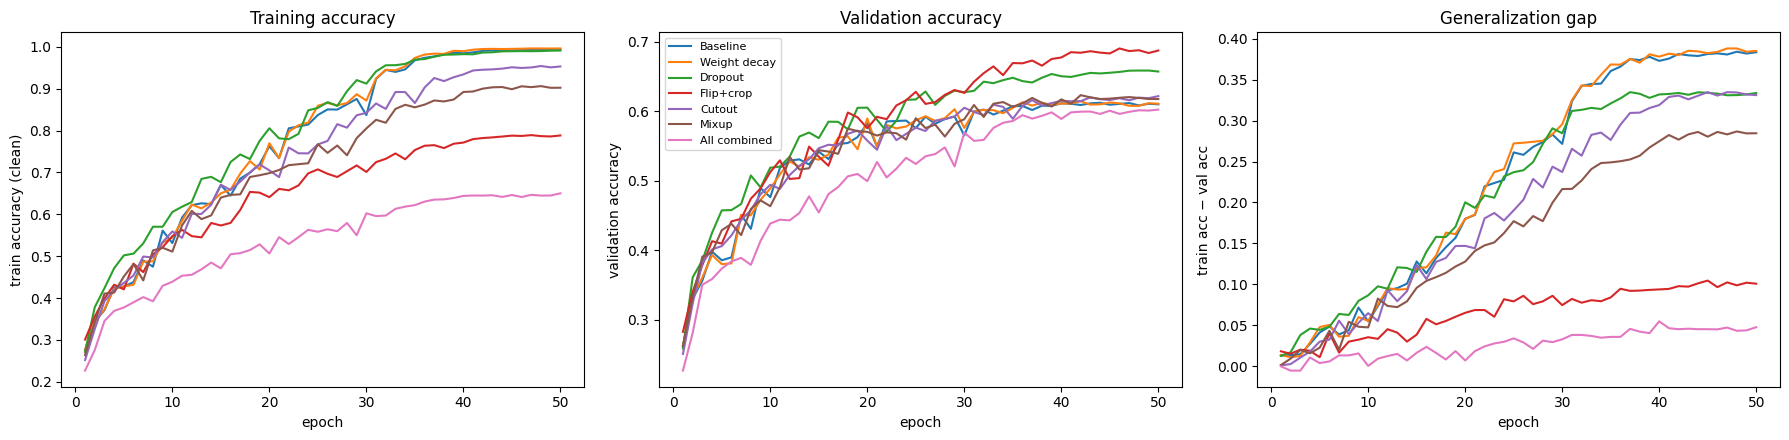

In [23]:
# tabulating and plotting
rows = []
for name, h in hists.items():
    tr, va = h["train_acc"][-1], h["val_acc"][-1]
    rows.append({"Setting": name, "Train acc": round(tr, 4), "Val acc": round(va, 4), "Gap": round(tr - va, 4)})
display(pd.DataFrame(rows).set_index("Setting"))

epochs = range(1, 51)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for name, h in hists.items():
    tr, va = np.array(h["train_acc"]), np.array(h["val_acc"])
    ax[0].plot(epochs, tr, label=name)
    ax[1].plot(epochs, va, label=name)
    ax[2].plot(epochs, tr - va, label=name)
ax[0].set(xlabel="epoch", ylabel="train accuracy (clean)", title="Training accuracy")
ax[1].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy")
ax[2].set(xlabel="epoch", ylabel="train acc − val acc", title="Generalization gap")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

With only 5k training images the baseline overfits heavily with a gap of 0.3836. Flip+crop gives the best validation accuracy and a much smaller gap, followed by dropout. All combined has the smallest gap but no better validation accuracy than the baseline.

- **Flip+crop** works best because it creates new label-preserving views of each image, which directly addresses the lack of data.
- **Dropout** helps moderately, but the network can still memorize the training set (train accuracy stays near 100%).
- **Weight decay, cutout and mixup** lower the gap slightly but do not improve validation accuracy at this training length.
- **All combined** underfits. Its training accuracy stays low, so the small gap reflects limited fitting rather than better generalization.

The baseline gap grows as training accuracy saturates, while the augmentation-based settings keep it much lower throughout.

(b) CIFAR-style plain and residual networks

CIFAR-style networks of depth 6n+2 (n = 1, 3, 9). The plain and residual families are identical except for the shortcut. The residual block outputs `ReLU(F(x) + shortcut(x))`, the plain block outputs `ReLU(F(x))`. All six networks are trained on the 45k training set with the same settings (SGD with momentum 0.9, lr 0.05, weight decay 5e-4, batch size 128, 20 epochs, cosine decay, seed 0, no augmentation).

In [24]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if residual and (stride != 1 or cin != cout):
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False),
                                          nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        layers, cin = [], 16
        for cout, stride in ((16, 1), (32, 2), (64, 2)):
            for b in range(n):
                layers.append(Block(cin, cout, stride if b == 0 else 1, residual))
                cin = cout
        self.stages = nn.Sequential(*layers)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(x.mean(dim=(2, 3))) # global average pooling

for n in (1, 3, 9):
    for res in (False, True):
        m = CifarNet(n, res)
        print(f"depth {6*n+2:2d} {'residual' if res else 'plain   '}  params = {sum(p.numel() for p in m.parameters()):,}")

depth  8 plain     params = 75,290
depth  8 residual  params = 78,042
depth 20 plain     params = 269,722
depth 20 residual  params = 272,474
depth 56 plain     params = 853,018
depth 56 residual  params = 855,770


In [25]:
# training
Xtr_g, ytr_g = train_x.to(device), train_y.to(device)
Xva_g, yva_g = val_x.to(device), val_y.to(device)

@torch.no_grad()
def val_acc(model, bs=1000):
    model.eval()
    return sum((model(Xva_g[i:i+bs]).argmax(1) == yva_g[i:i+bs]).sum().item()
               for i in range(0, len(Xva_g), bs)) / len(Xva_g)

def train_net(n, residual, epochs=20, bs=128, lr=0.05, wd=5e-4, seed=0):
    torch.manual_seed(seed)
    model = CifarNet(n, residual).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    g = torch.Generator(device=device).manual_seed(seed)
    losses = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_g), device=device, generator=g)
        running = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = F.cross_entropy(model(Xtr_g[idx]), ytr_g[idx])
            loss.backward()
            opt.step()
            running += loss.item() * len(idx)
        sched.step()
        losses.append(running / len(perm))
    return losses, val_acc(model)

res3b = {}
for n in (1, 3, 9):
    for residual in (False, True):
        key = (6 * n + 2, "residual" if residual else "plain")
        res3b[key] = train_net(n, residual)
        print(f"depth {key[0]:2d} {key[1]:8s} final train loss {res3b[key][0][-1]:.4f}  val acc {res3b[key][1]:.4f}")

depth  8 plain    final train loss 0.2356  val acc 0.7920
depth  8 residual final train loss 0.2157  val acc 0.7862
depth 20 plain    final train loss 0.0245  val acc 0.8292
depth 20 residual final train loss 0.0085  val acc 0.8294
depth 56 plain    final train loss 1.1461  val acc 0.5170
depth 56 residual final train loss 0.0038  val acc 0.8400


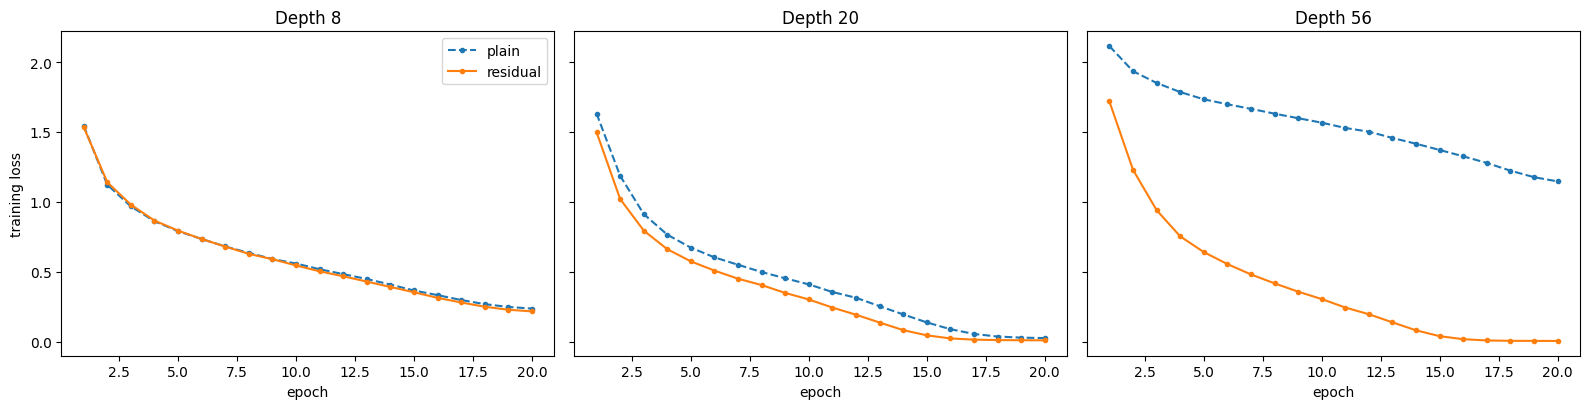

Final train loss  Val acc
Depth Family                             
8     plain               0.2356   0.7920
      residual            0.2157   0.7862
20    plain               0.0245   0.8292
      residual            0.0085   0.8294
56    plain               1.1461   0.5170
      residual            0.0038   0.8400

In [26]:
# plotting
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for a, d in zip(ax, (8, 20, 56)):
    for fam, style in (("plain", "--"), ("residual", "-")):
        a.plot(range(1, 21), res3b[(d, fam)][0], style, marker="o", markersize=3, label=fam)
    a.set(title=f"Depth {d}", xlabel="epoch")
ax[0].set_ylabel("training loss")
ax[0].legend()
plt.tight_layout(); plt.show()

import pandas as pd
display(pd.DataFrame([{"Depth": d, "Family": f, "Final train loss": round(l[-1], 4), "Val acc": round(v, 4)}
                      for (d, f), (l, v) in res3b.items()]).set_index(["Depth", "Family"]))

At depth 8 the plain and residual networks have almost identical training loss curves. At depth 20 the residual network trains slightly faster. At depth 56 the gap is large where the plain network reaches a final training loss of 1.1461, while the residual network reaches 0.004. Going from depth 20 to 56, the plain network gets much worse, whereas the residual network keeps improving slightly.

- **Depth 8:** the network is shallow enough that gradients reach all layers easily, so the shortcut makes no visible difference.
- **Depth 20:** the shortcut speeds up optimization slightly, but both families fit the training set.
- **Depth 56:** the plain network trains worse than the shallower plain networks. A deeper plain network could be similar to a shallower one reslting in an optimization failure. The high training loss shows the poor validation accuracy is underfitting.

The shortcut gives gradients a direct path to earlier layers, and each block only learns a correction `F(x)`, so having extra depth does not matter. This is why residual blocks fix this issue.

### Task 4: CNN

CIFAR-style residual network with widths chosen so that the parameter count is ≤ 500k. It uses SGD with Nesterov momentum 0.9, learning rate 0.1, weight decay 5e-4, label smoothing 0.1, batch size 128, 20 epochs and flip+crop augmentation.

In [27]:
class Net(nn.Module):
    def __init__(self, n=3, widths=(20, 40, 80), residual=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU())
        layers, cin = [], widths[0]
        for w, s in zip(widths, (1, 2, 2)):
            for b in range(n):
                layers.append(Block(cin, w, s if b == 0 else 1, residual))
                cin = w
        self.stages = nn.Sequential(*layers)
        self.fc = nn.Linear(widths[-1], 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.fc(self.stages(self.stem(x)).mean(dim=(2, 3)))

def n_params(**kw):
    return sum(p.numel() for p in Net(**kw).parameters())

print("params:", n_params(n=3, widths=(20, 40, 80)))

params: 424910


In [28]:
def train_final(residual=True, aug=True, wd=5e-4, ls=0.1, n=3, widths=(20, 40, 80),
                epochs=20, bs=128, lr=0.1, seed=0, return_model=False):
    torch.manual_seed(seed); np.random.seed(seed)
    model = Net(n, widths, residual).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    steps_per_ep = (len(Xtr_g) + bs - 1) // bs
    total, warm = epochs * steps_per_ep, steps_per_ep
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + np.cos(np.pi * (s - warm) / (total - warm))))
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_g), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb = flip_crop(Xtr_g[idx]) if aug else Xtr_g[idx]
            opt.zero_grad()
            F.cross_entropy(model(xb), ytr_g[idx], label_smoothing=ls).backward()
            opt.step(); sched.step()
    va = val_acc(model)
    return (va, model) if return_model else va

Ablation

In [29]:
ablation = {
    "Full model":               dict(),
    "No shortcut (plain)":      dict(residual=False),
    "No augmentation":          dict(aug=False),
    "No weight decay":          dict(wd=0.0),
    "No label smoothing":       dict(ls=0.0),
}
abl = {}
for name, kw in ablation.items():
    abl[name] = train_final(**kw)
    print(f"{name:22s} val acc {abl[name]:.4f}")

display(pd.DataFrame({"Val acc": abl, "Δ vs full": {k: round(v - abl['Full model'], 4) for k, v in abl.items()}}).round(4))

Full model             val acc 0.9024
No shortcut (plain)    val acc 0.8854
No augmentation        val acc 0.8550
No weight decay        val acc 0.8830
No label smoothing     val acc 0.9004


,Val acc,Δ vs full
Full model,0.9024,0.0000
No shortcut (plain),0.8854,-0.0170
No augmentation,0.8550,-0.0474
No weight decay,0.8830,-0.0194
No label smoothing,0.9004,-0.0020


According to the results above, dropping flip+crop augmentation had the biggest effect as validation accuracy fell from 90.2% to 85.5%. This happens because with only 20 epochs the network starts memorizing the 45k training images and augmentation gives it new views of each one. Removing weight decay or the residual shortcut lowered accuracy by roughly 2 points each. Weight decay regularizes the weights, and the shortcut makes the deeper network easier to optimize. Label smoothing changed accuracy by only 0.2 points.

Final test evaluation

In [30]:
import torchvision
test = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)
Xte = torch.from_numpy(test.data).permute(0, 3, 1, 2).float().div(255.0)
Xte = ((Xte - mean) / std).to(device)
yte = torch.tensor(test.targets).to(device)

va, final_model = train_final(return_model=True)
final_model.eval()
with torch.no_grad():
    test_acc = sum((final_model(Xte[i:i+1000]).argmax(1) == yte[i:i+1000]).sum().item()
                   for i in range(0, len(Xte), 1000)) / len(Xte)
print(f"params {n_params():,} | val acc {va:.4f} | TEST acc {test_acc:.4f}")

params 424,910 | val acc 0.9068 | TEST acc 0.9066


The final model has 424,910 parameters and was trained for 20 epochs. It reaches 90.68% accuracy on the validation split and 90.66% on the test set. The close match between validation and test accuracy suggests that tuning on the validation split did not overfit to it and that the result should generalize to unseen data.